In [12]:
import numpy as np
import matplotlib.pyplot as plt
import os
import xtrack as xt
import pickle
import at

from xtrack.tpsa._knobs import KnobParameters

In [2]:
with open('candidates/n01_02_01_01/ring.pkl', 'rb') as file:
    ring = pickle.load(file)

xcell = at.load.xsuite.line_from_lattice(ring, match_model=True)

/gpfs/offline1/staff/common/alfpet/git/lattice_design/.venv/lib64/python3.12/site-packages/at/load/xsuite.py:373: AtWarning: Element 'corrh_ac' is replaced by a Marker
  return xsclass.from_at(match_model=match_model, **atelem.to_file())
/gpfs/offline1/staff/common/alfpet/git/lattice_design/.venv/lib64/python3.12/site-packages/at/load/xsuite.py:373: AtWarning: Element 'corrv_ac' is replaced by a Marker
  return xsclass.from_at(match_model=match_model, **atelem.to_file())
/gpfs/offline1/staff/common/alfpet/git/lattice_design/.venv/lib64/python3.12/site-packages/at/load/xsuite.py:373: AtWarning: Element 'corrv' is replaced by a Marker
  return xsclass.from_at(match_model=match_model, **atelem.to_file())
/gpfs/offline1/staff/common/alfpet/git/lattice_design/.venv/lib64/python3.12/site-packages/at/load/xsuite.py:373: AtWarning: Element 'corrh' is replaced by a Marker
  return xsclass.from_at(match_model=match_model, **atelem.to_file())
/gpfs/offline1/staff/common/alfpet/git/lattice_design/

Loading line from dict:   0%|          | 0/368 [00:00<?, ?it/s]

Done loading line from dict.           


/gpfs/offline1/staff/common/alfpet/git/lattice_design/.venv/lib64/python3.12/site-packages/xtrack/beam_elements/_common.py:193: FutureWarning: The 'yoshida4' integrator is now deprecated and will be removed in a future version. In the past this was equivalent to the present yoshida-6. To get the same behaviour, please use 'yoshida-6' instead. This deprecation is part of the interface cleanup in view of the 1.0 release.
  warn(


In [35]:

for e in xcell.elements:
    if hasattr(e, 'knl'):
        print(e)

View of Multipole(order=np.int64(3), inv_factorial_order=0.167, length=0.05, hxl=0, radiation_flag=np.int64(0), delta_taper=0, knl=[  0.    ,   0.    ,   0.    , 298.1448], ksl=[0., 0., 0., 0.], knl_rel=[0.], ksl_rel=[0.], main_order=np.int32(0), main_is_skew=False, isthick=True, num_multipole_kicks=np.int64(1), model='drift-kick-drift-expanded', integrator='yoshida-6', shift_x=0, shift_y=0, shift_s=0, rot_s_rad=0, rot_x_rad=0, rot_y_rad=0, rot_s_rad_no_frame=0, rot_shift_anchor=0)
View of Multipole(order=np.int64(3), inv_factorial_order=0.167, length=0.05, hxl=0, radiation_flag=np.int64(0), delta_taper=0, knl=[  0.    ,   0.    ,   0.    , 298.1448], ksl=[0., 0., 0., 0.], knl_rel=[0.], ksl_rel=[0.], main_order=np.int32(0), main_is_skew=False, isthick=True, num_multipole_kicks=np.int64(1), model='drift-kick-drift-expanded', integrator='yoshida-6', shift_x=0, shift_y=0, shift_s=0, rot_s_rad=0, rot_x_rad=0, rot_y_rad=0, rot_s_rad_no_frame=0, rot_shift_anchor=0)
View of Multipole(order=np

## Compare Twiss and dispersion

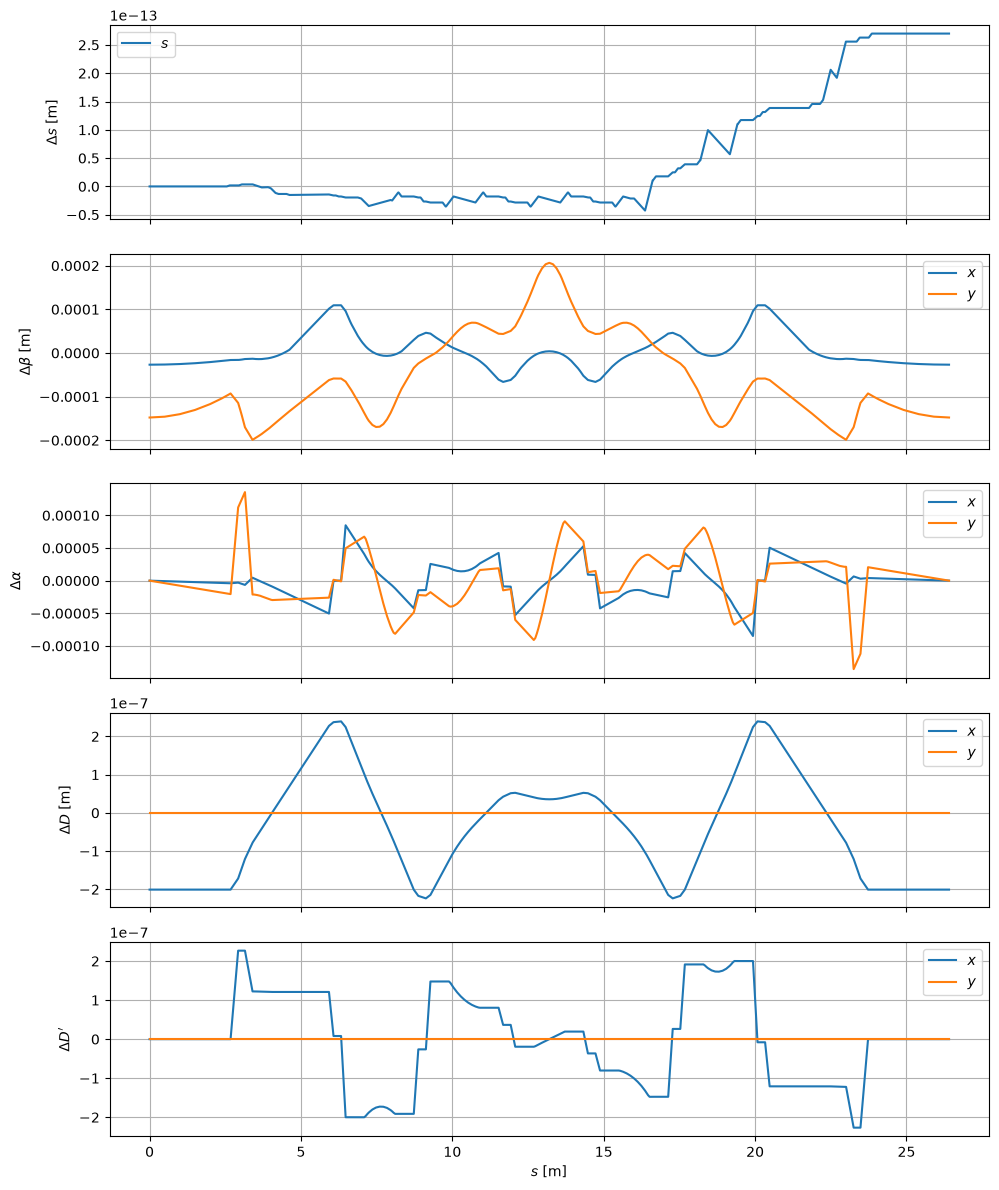

In [3]:
twiss = xcell.twiss(method='4d')
elemdata = ring.linopt4(at.All)[2]

# Number of rows common to all quantities
n = min(
    len(twiss.s),
    len(elemdata.s_pos),
    len(elemdata.beta),
    len(elemdata.alpha),
    len(elemdata.dispersion),
)

s = twiss.s[:n]

comparisons = [
    (
        r'$\Delta s$ [m]',
        [(twiss.s[:n] - elemdata.s_pos[:n], r'$s$')],
    ),
    (
        r'$\Delta\beta$ [m]',
        [
            (twiss.betx[:n] - elemdata.beta[:n, 0], r'$x$'),
            (twiss.bety[:n] - elemdata.beta[:n, 1], r'$y$'),
        ],
    ),
    (
        r'$\Delta\alpha$',
        [
            (twiss.alfx[:n] - elemdata.alpha[:n, 0], r'$x$'),
            (twiss.alfy[:n] - elemdata.alpha[:n, 1], r'$y$'),
        ],
    ),
    (
        r'$\Delta D$ [m]',
        [
            (twiss.dx[:n] - elemdata.dispersion[:n, 0], r'$x$'),
            (twiss.dy[:n] - elemdata.dispersion[:n, 2], r'$y$'),
        ],
    ),
    (
        r'$\Delta D^\prime$',
        [
            (twiss.dpx[:n] - elemdata.dispersion[:n, 1], r'$x$'),
            (twiss.dpy[:n] - elemdata.dispersion[:n, 3], r'$y$'),
        ],
    ),
]

fig, axes = plt.subplots(
    len(comparisons), 1,
    figsize=(10, 12),
    sharex=True,
)

for ax, (ylabel, curves) in zip(axes, comparisons):
    for values, label in curves:
        ax.plot(s, values, label=label)

    ax.set_ylabel(ylabel)
    ax.grid()
    ax.legend()

axes[-1].set_xlabel(r'$s$ [m]')

plt.tight_layout()
plt.show()

## Tracking test

In [4]:
xcell.particle_ref.p0c

LinkedArrayCpu([2.99999996e+09])

In [5]:
particles = xcell.build_particles()
print(particles)
xcell.track(particles)
print(particles)

Particles(q0=-1, mass0=5.11e+05, p0c=[2.99999996e+09], gamma0=[5870.85354275], beta0=[0.99999999], s=[0.], zeta=[0.], x=[0.], y=[0.], px=[0.], py=[0.], ptau=[0.], delta=[0.], rpp=[1.], rvv=[1.], chi=[1.], charge_ratio=[1.], weight=[1.], ax=[0.], ay=[0.], spin_x=[0.], spin_y=[0.], spin_z=[0.], anomalous_magnetic_moment=[0.], pdg_id=[0], particle_id=[0], at_element=[0], at_turn=[0], state=[1], parent_particle_id=[0], start_tracking_at_element=np.int64(-1), t_sim=8.81e-08)
Particles(q0=-1, mass0=5.11e+05, p0c=[2.99999996e+09], gamma0=[5870.85354275], beta0=[0.99999999], s=[0.], zeta=[0.], x=[0.], y=[0.], px=[0.], py=[0.], ptau=[0.], delta=[0.], rpp=[1.], rvv=[1.], chi=[1.], charge_ratio=[1.], weight=[1.], ax=[0.], ay=[0.], spin_x=[0.], spin_y=[0.], spin_z=[0.], anomalous_magnetic_moment=[0.], pdg_id=[0], particle_id=[0], at_element=[0], at_turn=[1], state=[1], parent_particle_id=[0], start_tracking_at_element=np.int64(-1), t_sim=8.81e-08)


## TPSA

In [6]:
print('Particle comparison')
tpsa = xt.ParticlesTpsa(order=2, pdg_id_0='electron', p0c=xcell.particle_ref.p0c)
particles = tpsa.to_particles()

xcell.track(tpsa)
xcell.track(particles)

print(tpsa.to_particles())
print(particles)

particles = xcell.build_particles()
xcell.track(particles)
print(particles)

Particle comparison
Particles(q0=-1, mass0=5.11e+05, p0c=[2.99999996e+09], gamma0=[5870.85355068], beta0=[0.99999999], s=[0.], zeta=[0.], x=[0.], y=[0.], px=[0.], py=[0.], ptau=[2.22044605e-16], delta=[0.], rpp=[1.], rvv=[1.], chi=[1.], charge_ratio=[1.], weight=[1.], ax=[0.], ay=[0.], spin_x=[0.], spin_y=[0.], spin_z=[0.], anomalous_magnetic_moment=[0.], pdg_id=[11], particle_id=[0], at_element=[0], at_turn=[0], state=[1], parent_particle_id=[0], start_tracking_at_element=np.int64(-1), t_sim=0)
Particles(q0=-1, mass0=5.11e+05, p0c=[2.99999996e+09], gamma0=[5870.85355068], beta0=[0.99999999], s=[0.], zeta=[0.], x=[0.], y=[0.], px=[0.], py=[0.], ptau=[2.22044605e-16], delta=[0.], rpp=[1.], rvv=[1.], chi=[1.], charge_ratio=[1.], weight=[1.], ax=[0.], ay=[0.], spin_x=[0.], spin_y=[0.], spin_z=[0.], anomalous_magnetic_moment=[0.], pdg_id=[11], particle_id=[0], at_element=[0], at_turn=[1], state=[1], parent_particle_id=[0], start_tracking_at_element=np.int64(-1), t_sim=0)
Particles(q0=-1, m

## GTPSA

In [7]:
print('Particle comparison')
tpsa = xt.ParticlesTpsa(order=1, pdg_id_0='electron', p0c=xcell.particle_ref.p0c)
particles = tpsa.to_particles()

xcell.track(tpsa)
xcell.track(particles)

print(tpsa.to_particles())
print(particles)

particles = xcell.build_particles()
xcell.track(particles)
print(particles)

Particle comparison
Particles(q0=-1, mass0=5.11e+05, p0c=[2.99999996e+09], gamma0=[5870.85355068], beta0=[0.99999999], s=[0.], zeta=[0.], x=[0.], y=[0.], px=[0.], py=[0.], ptau=[2.22044605e-16], delta=[0.], rpp=[1.], rvv=[1.], chi=[1.], charge_ratio=[1.], weight=[1.], ax=[0.], ay=[0.], spin_x=[0.], spin_y=[0.], spin_z=[0.], anomalous_magnetic_moment=[0.], pdg_id=[11], particle_id=[0], at_element=[0], at_turn=[0], state=[1], parent_particle_id=[0], start_tracking_at_element=np.int64(-1), t_sim=0)
Particles(q0=-1, mass0=5.11e+05, p0c=[2.99999996e+09], gamma0=[5870.85355068], beta0=[0.99999999], s=[0.], zeta=[0.], x=[0.], y=[0.], px=[0.], py=[0.], ptau=[2.22044605e-16], delta=[0.], rpp=[1.], rvv=[1.], chi=[1.], charge_ratio=[1.], weight=[1.], ax=[0.], ay=[0.], spin_x=[0.], spin_y=[0.], spin_z=[0.], anomalous_magnetic_moment=[0.], pdg_id=[11], particle_id=[0], at_element=[0], at_turn=[1], state=[1], parent_particle_id=[0], start_tracking_at_element=np.int64(-1), t_sim=0)
Particles(q0=-1, m

In [8]:
for i, e in enumerate(xcell):
    print(i, e)

0 View of Drift(length=0.5, model='expanded')
1 View of Drift(length=0.5, model='expanded')
2 View of Drift(length=0.5, model='expanded')
3 View of Drift(length=0.5, model='expanded')
4 View of Drift(length=0.321, model='expanded')
5 View of Marker()
6 View of Drift(length=0.025, model='expanded')
7 View of Marker()
8 View of Drift(length=0.025, model='expanded')
9 View of Drift(length=0.01, model='expanded')
10 View of Marker()
11 View of Marker()
12 View of Drift(length=0.048, model='expanded')
13 View of Drift(length=0.025, model='expanded')
14 View of Marker()
15 View of Drift(length=0.025, model='expanded')
16 View of Drift(length=0.025, model='expanded')
17 View of Marker()
18 View of Drift(length=0.025, model='expanded')
19 View of Drift(length=0.021, model='expanded')
20 View of Multipole(order=np.int64(3), inv_factorial_order=0.167, length=0.05, hxl=0, radiation_flag=np.int64(0), delta_taper=0, knl=[  0.    ,   0.    ,   0.    , 298.1448], ksl=[0., 0., 0., 0.], knl_rel=[0.], k

In [10]:
import madng_tpsa
import xtrack as xt
import xtrack.tpsa as xtpsa

# Nominal quadrupole strength
k1_0 = xcell[23].knl[1]

# Create a TPSA descriptor:
#   6 phase-space variables
#   1st-order expansion
#   1 additional parameter
descriptor = madng_tpsa.Descriptor(
    6, 1,
    num_params=1,
    param_order=1,
)

# Parameter 0 = nominal k1
k1_tpsa = descriptor.param(1, k1_0)

# Make element 23 depend on this parameter
xcell[23].knl[1] = k1_tpsa

ValueError: setting an array element with a sequence.

In [16]:
import madng_tpsa
import xtrack as xt
import xtrack.tpsa as xtpsa
from xtrack.tpsa._knobs import KnobParameters

# Nominal value
k1_0 = xcell[23].knl[1]

# TPSA descriptor: 6 phase-space variables + 1 parameter
descriptor = madng_tpsa.Descriptor(
    6, 1,
    num_params=1,
    param_order=1,
)

# Create the knob parameter
knobs = KnobParameters(xcell, ['k1'], descriptor)

# Parameterize the k1 entry of element 23
knobs.add_knob(
    xcell[23].knl[1],
    descriptor.param(1, k1_0),
)

KeyError: "knob 'k1' is not a line variable"

In [ ]:
import xtrack as xt
import xdeps
import madng_tpsa

print("xtrack:", xt.__version__)
print("xdeps:", xdeps.__version__)
print("madng_tpsa:", madng_tpsa.__version__)

import xtrack.tpsa as xtpsa
print(xtpsa.__file__)
print(dir(xtpsa))

xtrack: 0.114.1
xdeps: 0.10.21
madng_tpsa: 0.3.1
/gpfs/offline1/staff/common/alfpet/git/lattice_design/.venv/lib64/python3.12/site-packages/xtrack/tpsa/__init__.py
['COORDS', 'ParticlesTpsa', 'TpsaOptics', '__all__', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', 'optics', 'particles']
